In [ ]:
# Google Colab : télécharger les données de cette séance / download this session's data
import os, urllib.request
BASE = "https://raw.githubusercontent.com/Marzoug-Nabil/Nabil/main/academic/teaching/fsci6222/materials/tp1/"
for f in ['departements_info.csv', 'employes_techno.csv']:
    os.makedirs('data', exist_ok=True)
    for dst in (f, os.path.join('data', f)):
        if not os.path.exists(dst):
            urllib.request.urlretrieve(BASE + f, dst)


# FSCI 6222 — TP1 Partie 1 — CORRIGÉ
## Python, NumPy, Pandas, Nettoyage et Visualisation

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

## Q1 — Python de base (10 pts)
### 1.1 Fonctions (4 pts)

In [18]:
# 1.1 Fonction classifier_salaire (4 pts)
def classifier_salaire(salaire):
    if salaire < 55000:
        return "Junior"
    elif salaire <= 80000:
        return "Intermédiaire"
    else:
        return "Senior"

# Tests
print(classifier_salaire(48000))   # Junior
print(classifier_salaire(65000))   # Intermédiaire
print(classifier_salaire(92000))   # Senior

Junior
Intermédiaire
Senior


**Barème :** Fonction correcte 2pts, if/elif/else 1pt, tests 1pt

### 1.2 Listes et dictionnaires (3 pts)

In [19]:
# a) Liste (0.5 pt)
salaires = [48000, 65000, 92000, 55000, 78000, 105000, 51000, 72000]

# b) List comprehension (1 pt)
salaires_hauts = [s for s in salaires if s > 70000]
print(f"Salaires > 70k : {salaires_hauts}")  # [92000, 78000, 105000, 72000]

# c) Dictionnaire (1.5 pts)
stats_salaires = {
    "min": min(salaires),
    "max": max(salaires),
    "moyenne": sum(salaires) / len(salaires),
    "nombre": len(salaires)
}
print(f"Stats : {stats_salaires}")

Salaires > 70k : [92000, 78000, 105000, 72000]
Stats : {'min': 48000, 'max': 105000, 'moyenne': 70750.0, 'nombre': 8}


### 1.3 Boucles (3 pts)

In [4]:
# a) Boucle for avec affichage (1 pt)
for s in salaires:
    niveau = classifier_salaire(s)
    print(f"Salaire: {s}$ → {niveau}")

# b) Compteur par niveau (2 pts)
compteur = {"Junior": 0, "Intermédiaire": 0, "Senior": 0}
for s in salaires:
    niveau = classifier_salaire(s)
    compteur[niveau] += 1

print(f"\nRépartition : {compteur}")
# Junior: 2, Intermédiaire: 4, Senior: 2

Salaire: 48000$ → Junior
Salaire: 65000$ → Intermédiaire
Salaire: 92000$ → Senior
Salaire: 55000$ → Intermédiaire
Salaire: 78000$ → Intermédiaire
Salaire: 105000$ → Senior
Salaire: 51000$ → Junior
Salaire: 72000$ → Intermédiaire

Répartition : {'Junior': 2, 'Intermédiaire': 4, 'Senior': 2}


---
## Q2 — NumPy (10 pts)
### 2.1 Opérations vectorielles (4 pts)

In [20]:
# a) Création (0.5 pt)
heures_formation = np.array([45, 20, 35, 30, 60, 40, 15, 50, 25, 30])
nb_projets = np.array([12, 4, 3, 8, 18, 11, 6, 10, 9, 2])

# b) Ratio (1 pt)
ratio = heures_formation / nb_projets
print(f"Ratio : {ratio.round(2)}")

# c) Statistiques (1 pt)
print(f"Moyenne ratio : {np.mean(ratio):.2f}")
print(f"Écart-type    : {np.std(ratio):.2f}")
print(f"Médiane       : {np.median(ratio):.2f}")

# d) Masque booléen (1.5 pts)
masque = ratio > 5
print(f"\nEmployés avec ratio > 5 : {np.sum(masque)}")
print(f"Leurs ratios : {ratio[masque].round(2)}")

Ratio : [ 3.75  5.   11.67  3.75  3.33  3.64  2.5   5.    2.78 15.  ]
Moyenne ratio : 5.64
Écart-type    : 3.99
Médiane       : 3.75

Employés avec ratio > 5 : 2
Leurs ratios : [11.67 15.  ]


### 2.2 Statistiques avec NumPy (3 pts)

In [6]:
# a) Array (0.5 pt)
notes_eval = np.array([4.5, 3.2, 3.8, 4.0, 4.8, 4.2, 3.5, 4.3, 4.1, 3.0])

# b) Statistiques (1.5 pts)
print(f"Somme    : {np.sum(notes_eval)}")
print(f"Min      : {np.min(notes_eval)}")
print(f"Max      : {np.max(notes_eval)}")
print(f"Argmax   : {np.argmax(notes_eval)} (indice {np.argmax(notes_eval)} = {notes_eval[np.argmax(notes_eval)]})")
print(f"Variance : {np.var(notes_eval):.4f}")

# c) Normalisation (1 pt)
notes_norm = (notes_eval - np.mean(notes_eval)) / np.std(notes_eval)
print(f"\nNotes normalisées : {notes_norm.round(3)}")
print(f"Moyenne normalisée : {np.mean(notes_norm):.10f} (≈ 0 ✓)")

Somme    : 39.4
Min      : 3.0
Max      : 4.8
Argmax   : 4 (indice 4 = 4.8)
Variance : 0.2924

Notes normalisées : [ 1.036 -1.368 -0.259  0.111  1.59   0.481 -0.814  0.666  0.296 -1.738]
Moyenne normalisée : 0.0000000000 (≈ 0 ✓)


### 2.3 Benchmark (3 pts)

In [7]:
# a) Arrays aléatoires (0.5 pt)
np.random.seed(42)
a = np.random.rand(100000)
b = np.random.rand(100000)

# b) Boucle Python (1 pt)
debut = time.time()
resultat_boucle = 0
for i in range(len(a)):
    resultat_boucle += a[i] * b[i]
temps_boucle = time.time() - debut
print(f"Boucle  : {resultat_boucle:.4f} en {temps_boucle:.4f}s")

# c) NumPy vectorisé (1.5 pts)
debut = time.time()
resultat_numpy = np.dot(a, b)
temps_numpy = time.time() - debut
print(f"NumPy   : {resultat_numpy:.4f} en {temps_numpy:.6f}s")

print(f"\nRapport : NumPy est {temps_boucle/temps_numpy:.0f}x plus rapide!")

Boucle  : 25026.0999 en 0.0410s
NumPy   : 25026.0999 en 0.000554s

Rapport : NumPy est 74x plus rapide!


---
## Q3 — Pandas et Nettoyage (18 pts)
### 3.1 Chargement et exploration (3 pts)

In [21]:
# a) Chargement (0.5 pt)
df = pd.read_csv('employes_techno.csv')

# b) Dimensions et aperçu (1 pt)
print(f"Dimensions : {df.shape}")
print(f"\n{df.head()}")
print(f"\nTypes :\n{df.dtypes}")

# c) Info et describe (1.5 pts)
df.info()
print("\n")
print(df.describe().round(2))

# Problèmes identifiés :
# 1. Valeurs manquantes (salaire, annees_experience, note_evaluation)
# 2. Doublons (ligne 31 = copie de ligne 1)
# 3. heures_formation contient "deux" (type object au lieu de numérique)
# 4. date_embauche au format incorrect (ligne 34 : "15-06-2022")
# 5. Incohérences textuelles : "moncton" vs "Moncton", "contractuel" vs "Contractuel"
# 6. Salaire aberrant : 1 650 000$ (probablement 65 000$)
# 7. Heures de formation négatives : -35

Dimensions : (42, 16)

   id       nom  prenom     departement                    poste        ville  \
0   1  Tremblay  Sophie   Développement      Développeuse Senior      Moncton   
1   2    Landry    Marc         Données          Analyste Junior       Dieppe   
2   3   Cormier   Julie   Développement      Développeuse Junior      Moncton   
3   4   LeBlanc  Pierre  Infrastructure   Administrateur Système  Fredericton   
4   5   Richard    Anne         Données  Scientifique de données      Moncton   

   salaire  annees_experience heures_formation  nb_projets  note_evaluation  \
0  82000.0                8.0               45          12              4.5   
1  52000.0                2.0               20           4              3.2   
2  55000.0                1.0               35           3              3.8   
3  68000.0                5.0               30           8              4.0   
4  95000.0               10.0               60          18              4.8   

   satisfaction

### 3.2 Nettoyage complet (9 pts)

In [22]:
# a) Valeurs manquantes (2 pts)
print("NaN par colonne :")
print(df.isnull().sum())
print()

df['salaire'] = df['salaire'].fillna(df['salaire'].median())
df['annees_experience'] = df['annees_experience'].fillna(df['annees_experience'].median())
df['note_evaluation'] = df['note_evaluation'].fillna(df['note_evaluation'].mean())
print(f"NaN après traitement : {df.isnull().sum().sum()}")

# b) Doublons (1 pt)
print(f"\nDoublons avant : {df.duplicated().sum()}")
df = df.drop_duplicates()
print(f"Doublons après : {df.duplicated().sum()}")
print(f"Lignes restantes : {len(df)}")

# c) Types incorrects (2 pts)
print(f"\nValeurs uniques heures_formation : {df['heures_formation'].unique()}")
df['heures_formation'] = df['heures_formation'].replace('deux', '2')
df['heures_formation'] = pd.to_numeric(df['heures_formation'])
print(f"Type heures_formation : {df['heures_formation'].dtype}")

df['date_embauche'] = pd.to_datetime(df['date_embauche'], errors='coerce')
print(f"Type date_embauche : {df['date_embauche'].dtype}")

# d) Incohérences textuelles (2 pts)
df['ville'] = df['ville'].str.capitalize()
df['type_contrat'] = df['type_contrat'].str.capitalize()
print(f"\nVilles : {df['ville'].unique()}")
print(f"Contrats : {df['type_contrat'].unique()}")

# e) Valeurs aberrantes (2 pts)
print(f"\nHeures négatives : {(df['heures_formation'] < 0).sum()}")
df.loc[df['heures_formation'] < 0, 'heures_formation'] = np.nan
df['heures_formation'] = df['heures_formation'].fillna(df['heures_formation'].median())

print(f"Salaire max avant : {df['salaire'].max()}")
df.loc[df['salaire'] > 1000000, 'salaire'] = 65000
print(f"Salaire max après : {df['salaire'].max()}")

NaN par colonne :
id                   0
nom                  0
prenom               0
departement          0
poste                0
ville                0
salaire              1
annees_experience    1
heures_formation     0
nb_projets           0
note_evaluation      1
satisfaction         0
age                  0
sexe                 0
type_contrat         0
date_embauche        0
dtype: int64

NaN après traitement : 0

Doublons avant : 0
Doublons après : 0
Lignes restantes : 42

Valeurs uniques heures_formation : <StringArray>
[  '45',   '20',   '35',   '30',   '60',   '40',   '15',   '50',   '25',
   '55',   '42',   '28',   '18',   '65',   '12',   '48',   '58',   '38',
   '10',   '32',   '22',   '52',   '62',   '16', 'deux',   '34',    '8',
  '-35']
Length: 28, dtype: str
Type heures_formation : int64
Type date_embauche : datetime64[us]

Villes : <StringArray>
['Moncton', 'Dieppe', 'Fredericton']
Length: 3, dtype: str
Contrats : <StringArray>
['Permanent', 'Contractuel']
Length: 2,

### 3.3 Sélection, filtrage et agrégation (3 pts)

In [10]:
# a) Filtrage (1 pt)
dev_senior = df[(df['departement'] == 'Développement') & (df['salaire'] > 70000)]
print(f"Développeurs avec salaire > 70k : {len(dev_senior)}")
print(dev_senior[['nom', 'prenom', 'salaire']])

# b) Salaire moyen par département (1 pt)
sal_dept = df.groupby('departement')['salaire'].mean().round(0)
print(f"\nSalaire moyen par département :")
print(sal_dept.sort_values(ascending=False))
print(f"\nPlus élevé : {sal_dept.idxmax()} ({sal_dept.max():,.0f}$)")

# c) Pivot table (1 pt)
pivot = pd.pivot_table(df, values='salaire', index='departement', columns='ville', aggfunc='mean').round(0)
print(f"\nTableau croisé salaire moyen :")
print(pivot)

Développeurs avec salaire > 70k : 7
         nom   prenom   salaire
0   Tremblay   Sophie   82000.0
5    Gallant      Luc   72000.0
12    Savoie    Diane   80000.0
15   Maillet  Jacques  105000.0
19  Levesque     Alex   72000.0
30  Tremblay   Sophie   82000.0
40    Nadeau   Sophie   75000.0

Salaire moyen par département :
departement
Infrastructure    74400.0
Données           74182.0
Développement     70286.0
Marketing         62571.0
Name: salaire, dtype: float64

Plus élevé : Infrastructure (74,400$)

Tableau croisé salaire moyen :
ville            Dieppe  Fredericton  Moncton
departement                                  
Données         63333.0      72000.0  79143.0
Développement   66400.0      80000.0  71500.0
Infrastructure  70000.0      78200.0  70750.0
Marketing       88000.0      82000.0  53600.0


### 3.4 Merge (3 pts)

In [12]:
# a) Charger (0.5 pt)
df_dept = pd.read_csv('departements_info.csv')
print(df_dept)

# b) Left merge (1 pt)
df = pd.merge(df, df_dept, on='departement', how='left')
print(f"\nAprès merge : {df.shape}")

# c) Pourcentage du budget (1.5 pts)
df['salaire_pct_budget'] = (df['salaire'] / df['budget_annuel'] * 100).round(2)
top = df.loc[df['salaire_pct_budget'].idxmax()]
print(f"\nPlus grand % du budget :")
print(f"  {top['prenom']} {top['nom']} ({top['departement']})")
print(f"  Salaire : {top['salaire']:,.0f}$ = {top['salaire_pct_budget']}% du budget")

      departement  budget_annuel  nb_postes_ouverts  etage    responsable
0   Développement        1200000                  5      3    Marc Dupuis
1         Données         800000                  3      4     Sarah Chen
2  Infrastructure         600000                  2      2     Jean Morin
3       Marketing         450000                  2      5  Lisa Tremblay

Après merge : (42, 20)

Plus grand % du budget :
  Eve Robichaud (Marketing)
  Salaire : 88,000$ = 19.56% du budget


---
## Q4 — Visualisation (12 pts)
### 4.1 Matplotlib (4 pts)

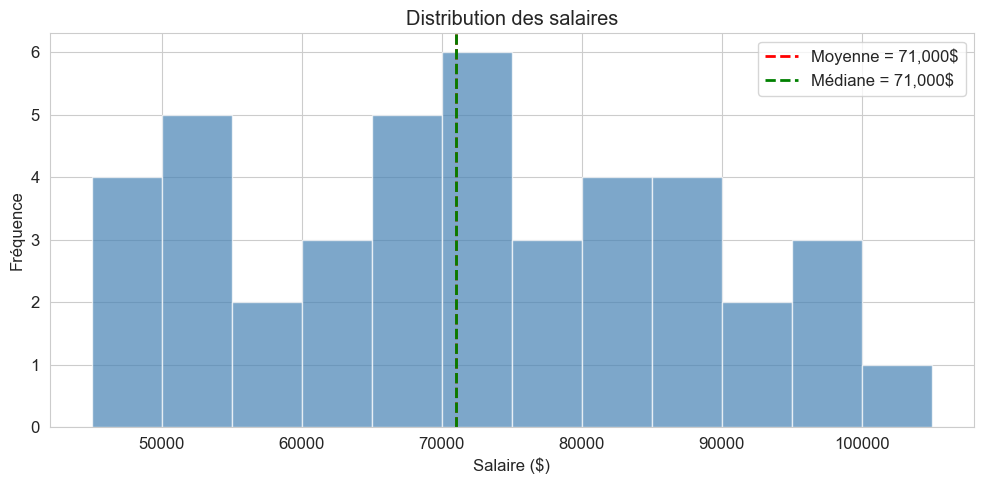

In [13]:
# 4.1a Histogramme (2 pts)
plt.figure(figsize=(10, 5))
plt.hist(df['salaire'], bins=12, color='steelblue', edgecolor='white', alpha=0.7)
plt.axvline(x=df['salaire'].mean(), color='red', linestyle='--', linewidth=2, label=f"Moyenne = {df['salaire'].mean():,.0f}$")
plt.axvline(x=df['salaire'].median(), color='green', linestyle='--', linewidth=2, label=f"Médiane = {df['salaire'].median():,.0f}$")
plt.title('Distribution des salaires')
plt.xlabel('Salaire ($)')
plt.ylabel('Fréquence')
plt.legend()
plt.tight_layout()
plt.show()

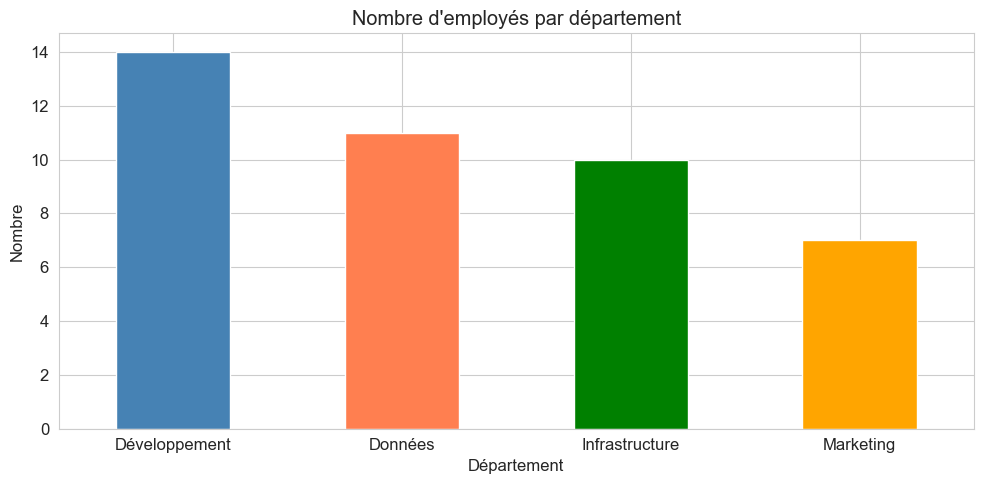

In [14]:
# 4.1b Barres (2 pts)
plt.figure(figsize=(10, 5))
counts = df['departement'].value_counts()
counts.plot(kind='bar', color=['steelblue', 'coral', 'green', 'orange'], edgecolor='white')
plt.title('Nombre d\'employés par département')
plt.xlabel('Département')
plt.ylabel('Nombre')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4.2 Seaborn (4 pts)

/var/folders/8z/3v_z80_10qq6rtk0_b4cbx200000gn/T/ipykernel_13814/4126301300.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='departement', y='salaire', palette='Set2')


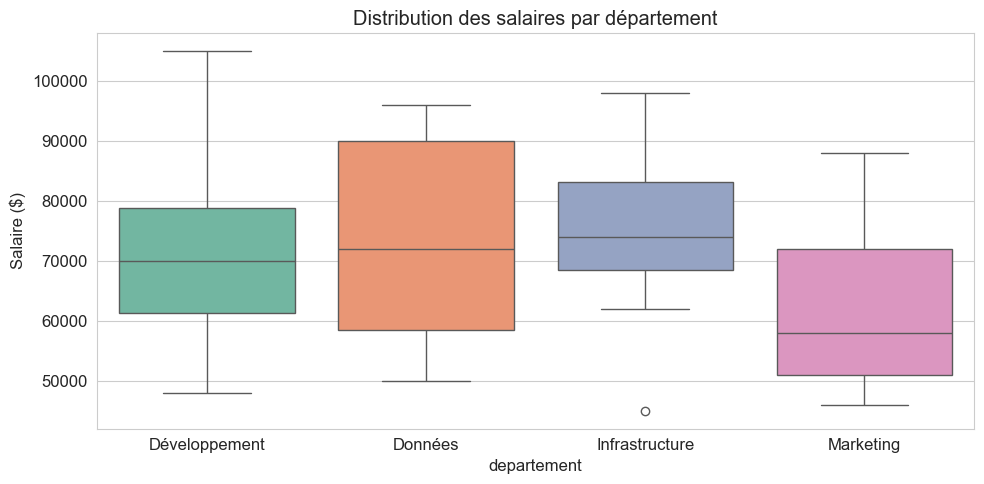

In [15]:
# 4.2a Boxplot (2 pts)
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='departement', y='salaire', palette='Set2')
plt.title('Distribution des salaires par département')
plt.ylabel('Salaire ($)')
plt.tight_layout()
plt.show()
# Le département avec la plus grande dispersion est celui avec la plus grande boîte (IQR)

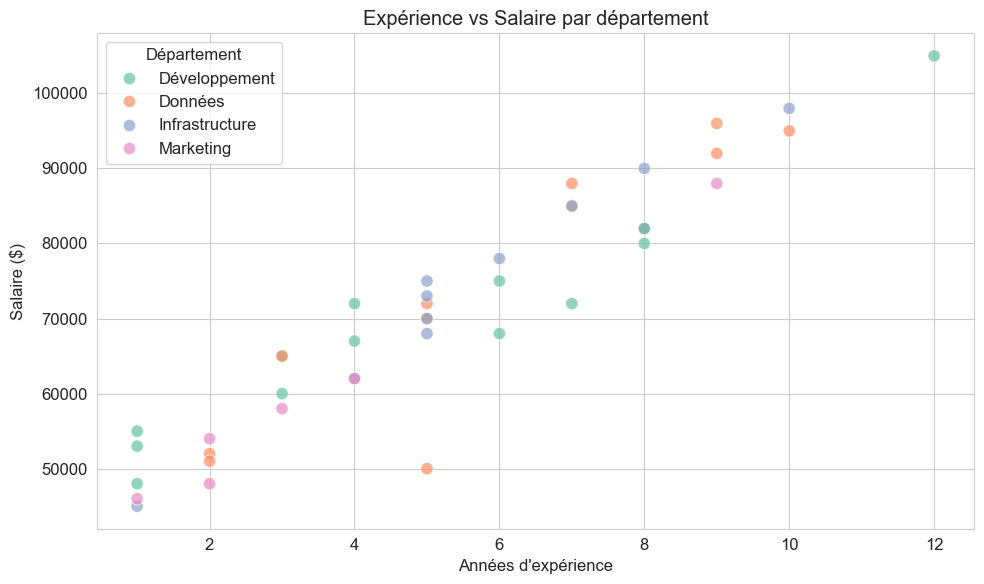

In [16]:
# 4.2b Scatter (2 pts)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='annees_experience', y='salaire', hue='departement', s=80, alpha=0.7, palette='Set2')
plt.title('Expérience vs Salaire par département')
plt.xlabel('Années d\'expérience')
plt.ylabel('Salaire ($)')
plt.legend(title='Département')
plt.tight_layout()
plt.show()

### 4.3 Dashboard (4 pts)

/var/folders/8z/3v_z80_10qq6rtk0_b4cbx200000gn/T/ipykernel_13814/1686283204.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='ville', y='salaire', ax=axes[0,1], palette='Set2')


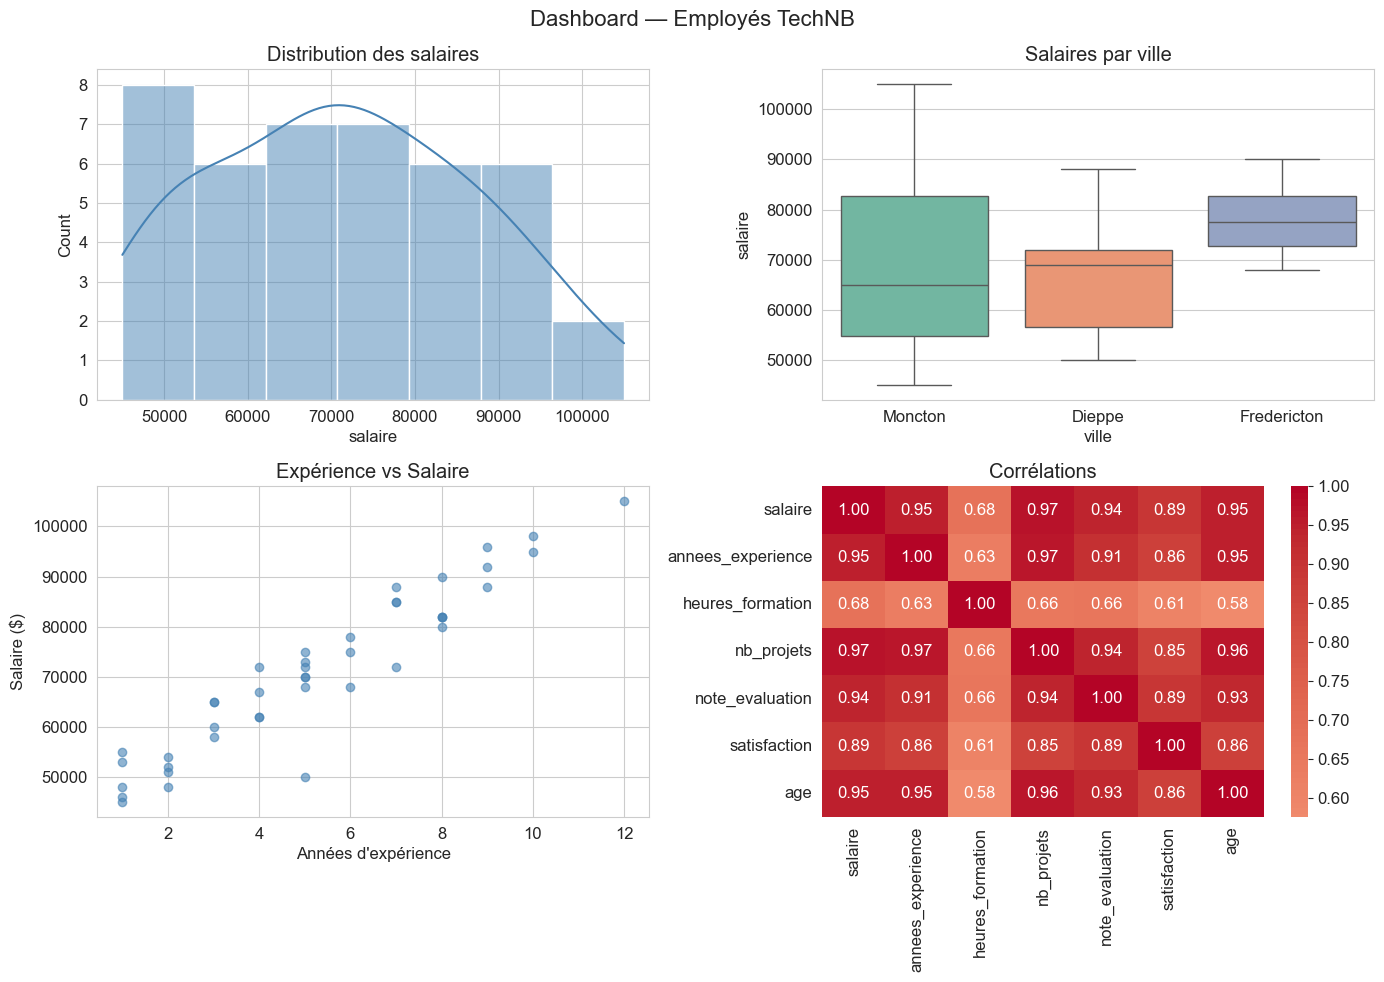

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogramme + KDE
sns.histplot(data=df, x='salaire', kde=True, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Distribution des salaires')

# 2. Boxplot par ville
sns.boxplot(data=df, x='ville', y='salaire', ax=axes[0,1], palette='Set2')
axes[0,1].set_title('Salaires par ville')

# 3. Scatter
axes[1,0].scatter(df['annees_experience'], df['salaire'], alpha=0.6, color='steelblue')
axes[1,0].set_title('Expérience vs Salaire')
axes[1,0].set_xlabel('Années d\'expérience')
axes[1,0].set_ylabel('Salaire ($)')

# 4. Heatmap corrélation
cols_num = ['salaire', 'annees_experience', 'heures_formation', 'nb_projets', 'note_evaluation', 'satisfaction', 'age']
corr = df[cols_num].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1,1], center=0)
axes[1,1].set_title('Corrélations')

plt.suptitle('Dashboard — Employés TechNB', fontsize=16)
plt.tight_layout()
plt.show()

---
*CORRIGÉ — FSCI 6222 — Université de Moncton — Été 2026*